# Network Intrusion Detection — Baseline ML Models

## MLOps Project | Chapter 1.1

### Project objective

The objective of this project is to develop a machine learning
model that detects malicious network traffic using the
NF-UNSW-NB15-v3 dataset.

We formulate this task as binary classification:

- **0 — Benign:** Normal network traffic
- **1 — Attack:** Potentially malicious network traffic

We will compare three baseline models:

1. Dummy Classifier
2. Logistic Regression
3. Random Forest

### Why this experiment matters

This initial experiment will establish a reproducible ML baseline.
Later, we will transform the notebook into Python scripts,
automate the experiment using DVC and GitHub Actions, deploy
the model, and monitor data drift.

### Main evaluation metrics

Because most records represent benign traffic, accuracy alone
is not sufficient. We will focus on:

- Precision: How many predicted attacks are real attacks?
- Recall: How many actual attacks were detected?
- F1-score: Balance between precision and recall.
- PR-AUC: Performance across precision-recall thresholds.
- Confusion matrix: Types of correct and incorrect predictions.


In [4]:

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

# General-purpose libraries
from pathlib import Path
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Machine learning utilities
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
)

# Model serialization
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)

# Reproducibility:
# Using the same seed makes random sampling and splitting
# produce consistent results across repeated experiments.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Paths: the notebook is located inside notebooks/
PROJECT_ROOT = Path("..").resolve()
DATA_PATH = PROJECT_ROOT / "data/raw/NF-UNSW-NB15-v3.csv"
MODEL_DIR = PROJECT_ROOT / "models"
EVALUATION_DIR = PROJECT_ROOT / "evaluation"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

# Initial experiment settings
SAMPLE_SIZE = 200_000
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.20

print("Project root:", PROJECT_ROOT)
print("Dataset found:", DATA_PATH.exists())
print("Random seed:", SEED)


Project root: /Users/arwaaldhuraibi/mlops-project-2026
Dataset found: True
Random seed: 42


In [5]:

# ============================================================
# 2. INSPECT DATASET STRUCTURE
# ============================================================

# Load only a few rows initially to inspect column names.
# This avoids loading the entire dataset into memory.
df_preview = pd.read_csv(DATA_PATH, nrows=10)

print("Number of columns:", df_preview.shape[1])
print("\nColumn names:")
print(df_preview.columns.tolist())

print("\nSample records:")
display(df_preview.head())

print("\nData types:")
display(df_preview.dtypes.to_frame("dtype"))

# Check whether the binary classification target is available.
assert "Label" in df_preview.columns, (
    "Expected target column 'Label' was not found."
)

print("\nTarget column 'Label' found successfully.")


Number of columns: 55

Column names:
['FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS', 'IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX', 'SRC_TO_DS

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,...,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1424242193040,1424242193043,59.166.0.2,4894,149.171.126.3,53,17,5.0,146,2,...,0,0,0,0,0,0,0,0,0,Benign
1,1424242192744,1424242193079,59.166.0.4,52671,149.171.126.6,31992,6,11.0,4704,28,...,0,91,12,19,0,90,12,19,0,Benign
2,1424242190649,1424242193109,59.166.0.0,47290,149.171.126.9,6881,6,37.0,13662,238,...,0,1843,10,119,0,1843,5,88,0,Benign
3,1424242193145,1424242193146,59.166.0.8,43310,149.171.126.7,53,17,5.0,146,2,...,0,0,0,0,0,0,0,0,0,Benign
4,1424242193239,1424242193241,59.166.0.1,45870,149.171.126.1,53,17,5.0,130,2,...,0,0,0,0,0,0,0,0,0,Benign



Data types:


,dtype
FLOW_START_MILLISECONDS,int64
FLOW_END_MILLISECONDS,int64
IPV4_SRC_ADDR,object
L4_SRC_PORT,int64
IPV4_DST_ADDR,object
L4_DST_PORT,int64
PROTOCOL,int64
L7_PROTO,float64
IN_BYTES,int64
IN_PKTS,int64



Target column 'Label' found successfully.


In [11]:

# ============================================================
# 3. LOAD A REPRODUCIBLE SAMPLE
# ============================================================

# Use reservoir sampling across chunks.
# This keeps a sample from the entire CSV rather than
# taking only the first records, which could introduce
# strong ordering bias.

rng = np.random.default_rng(SEED)

sample_parts = []
total_rows = 0

for chunk in pd.read_csv(DATA_PATH, chunksize=100_000):

    # Sample up to 10% of each chunk for a manageable
    # initial exploratory modeling experiment.
    sampled = chunk.sample(
        frac=0.10,
        random_state=SEED
    )

    sample_parts.append(sampled)
    total_rows += len(chunk)

    print(f"Processed {total_rows:,} rows", end="\r")

df = pd.concat(sample_parts, ignore_index=True)

# If the result is larger than our target size,
# take another reproducible random sample.
if len(df) > SAMPLE_SIZE:
    df = df.sample(
        n=SAMPLE_SIZE,
        random_state=SEED
    ).reset_index(drop=True)

print(f"\nOriginal rows processed: {total_rows:,}")
print(f"Rows selected for modeling: {len(df):,}")
print(f"Columns: {df.shape[1]}")

display(df.head())


Processed 2,365,424 rows
Original rows processed: 2,365,424
Rows selected for modeling: 200,000
Columns: 55


,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,...,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1421930323228,1421930323987,59.166.0.7,51789,149.171.126.0,25,6,37.0,37502,52,...,0,84,14,28,0,85,18,30,0,Benign
1,1421940756011,1421940756012,59.166.0.0,6729,149.171.126.6,58270,17,11.0,544,4,...,0,1,0,0,0,0,0,0,0,Benign
2,1421958544980,1421958545020,59.166.0.5,40834,149.171.126.1,11256,6,36.0,3598,60,...,0,4,0,0,0,4,0,0,0,Benign
3,1424225391662,1424225391689,59.166.0.4,52907,149.171.126.7,50889,6,36.0,3390,56,...,0,3,0,0,0,2,0,0,0,Benign
4,1421952130726,1421952130803,59.166.0.3,64488,149.171.126.1,21,6,37.0,481,9,...,0,40,7,11,0,40,8,11,0,Benign



## Data leakage and evaluation strategy

Data leakage occurs when information unavailable during real
prediction is used to train or evaluate a model.

This dataset contains network identifiers and timing information
that could allow models to memorize particular attack sources
instead of learning general network behavior.

We therefore exclude:
- IP addresses and network identifiers
- Source and destination ports in our first experiment
- Raw timestamps
- The attack-category target
- TTL-related features as an initial precaution

Another concern is duplicate network-flow records.

To reduce duplicate leakage, we will use a group-aware split:
records with identical selected feature values must remain
in the same dataset partition.

We will create three partitions:

- Training: used to fit the models.
- Validation: used to compare and select models.
- Test: reserved for final evaluation.

This is an initial group-aware baseline, not yet a complete
temporal generalization experiment.

A later experiment will investigate training on earlier
capture sessions and evaluating on later traffic.


Unique labels:
Label
0    189033
1     10967
Name: count, dtype: int64


,Class,Count,Percentage
0,Benign,189033,94.5165
1,Attack,10967,5.4835


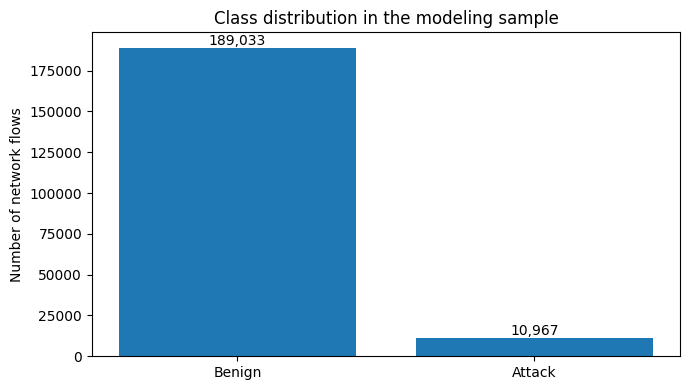

Majority-class baseline accuracy: 94.52%


In [12]:

# ============================================================
# 4. ANALYZE TARGET DISTRIBUTION
# ============================================================

print("Unique labels:")
print(df["Label"].value_counts(dropna=False))

# The dataset normally encodes Benign=0 and Attack=1.
# Handle numeric labels and common text representations.
label_text = df["Label"].astype(str).str.strip().str.lower()

label_mapping = {
    "0": 0,
    "0.0": 0,
    "benign": 0,
    "normal": 0,
    "1": 1,
    "1.0": 1,
    "attack": 1,
    "malicious": 1,
}

y = label_text.map(label_mapping)

if y.isna().any():
    raise ValueError(
        "Unexpected target values: "
        + str(df.loc[y.isna(), "Label"].unique())
    )

y = y.astype(int)

class_counts = y.value_counts().sort_index()

class_summary = pd.DataFrame({
    "Class": ["Benign", "Attack"],
    "Count": [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ]
})

class_summary["Percentage"] = (
    class_summary["Count"] / len(y) * 100
)

display(class_summary)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(class_summary["Class"], class_summary["Count"])
ax.set_title("Class distribution in the modeling sample")
ax.set_ylabel("Number of network flows")

for i, count in enumerate(class_summary["Count"]):
    ax.text(i, count, f"{count:,}", ha="center", va="bottom")

plt.tight_layout()
plt.savefig(EVALUATION_DIR / "class_distribution.png", dpi=150)
plt.show()

print(
    "Majority-class baseline accuracy:",
    f"{class_counts.max() / len(y):.2%}"
)


In [13]:

# ============================================================
# 5. SELECT FEATURES FOR MODELING
# ============================================================

# Remove targets and identifiers.
# Port numbers and TTL-related fields are also excluded
# from this initial conservative baseline.
excluded_columns = {
    "Label",
    "Attack",
    "FLOW_START_MILLISECONDS",
    "FLOW_END_MILLISECONDS",
    "IPV4_SRC_ADDR",
    "IPV4_DST_ADDR",
    "L4_SRC_PORT",
    "L4_DST_PORT",
    "PROTOCOL",
    "L7_PROTO",
    "IN_BYTES",
    "OUT_BYTES",
}

# IMPORTANT:
# IN_BYTES and OUT_BYTES can be legitimate behavioral
# features. We exclude them here only to begin with a
# conservative feature subset; we may reintroduce them
# after examining how they affect generalization.

# Automatically identify additional identifier-like columns.
for column in df.columns:
    name = column.upper()

    if any(token in name for token in [
        "IPV4_", "IPV6_", "IP_ADDR",
        "TIMESTAMP", "MILLISECONDS",
        "SRC_TO_DST", "DST_TO_SRC"
    ]) and any(token in name for token in [
        "ADDR", "TIMESTAMP", "MILLISECONDS", "TTL"
    ]):
        excluded_columns.add(column)

    if "TTL" in name:
        excluded_columns.add(column)

# Use numeric behavioral features.
numeric_columns = df.select_dtypes(
    include=[np.number]
).columns.tolist()

feature_columns = [
    col for col in numeric_columns
    if col not in excluded_columns
]

if not feature_columns:
    raise ValueError("No numeric features remained after filtering.")

X = df[feature_columns].copy()

# Treat infinities as missing values.
# Imputation will be learned from training data only.
X = X.replace([np.inf, -np.inf], np.nan)

# Remove features that contain only missing values.
empty_columns = X.columns[X.isna().all()].tolist()
X = X.drop(columns=empty_columns)
feature_columns = X.columns.tolist()

print("Selected feature count:", len(feature_columns))
print("\nSelected features:")
print(feature_columns)

print("\nExcluded columns:")
print(sorted(excluded_columns.intersection(df.columns)))

print("\nFeatures containing missing values:")
display(
    X.isna().sum().loc[lambda s: s > 0]
    .sort_values(ascending=False)
    .head(15)
)

assert X.shape[1] > 0
assert len(X) == len(y)


Selected feature count: 39

Selected features:
['IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'DURATION_IN', 'DURATION_OUT', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'FTP_COMMAND_RET_CODE', 'SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX', 'SRC_TO_DST_IAT_AVG', 'SRC_TO_DST_IAT_STDDEV', 'DST_TO_SRC_IAT_MIN', 'DST_TO_SRC_IAT_MAX', 'DST_TO_SRC_IAT_AVG', 'DST_TO_SRC_IAT_STDDEV']

Excluded columns:
['Attack', 'DNS_TTL_ANSWER', 'FLOW_DURATION_MILLISECONDS', 'FLOW_END_MILLISECO

SRC_TO_DST_SECOND_BYTES    10248
DST_TO_SRC_SECOND_BYTES    10248
dtype: int64

In [14]:

# ============================================================
# 6. GROUP-AWARE DATA SPLITTING
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

# Hash the selected feature vector.
# Identical feature vectors get the same group identifier.
# This helps avoid placing duplicate flows across splits.
groups = pd.util.hash_pandas_object(
    X,
    index=False
).to_numpy()

# First hold out 20% of groups for testing.
outer_split = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=SEED
)

train_val_idx, test_idx = next(
    outer_split.split(X, y, groups=groups)
)

# Then hold out 20% of the remaining groups
# for validation. This gives approximately 64/16/20,
# although row proportions can differ with group sizes.
inner_split = GroupShuffleSplit(
    n_splits=1,
    test_size=VALIDATION_SIZE,
    random_state=SEED
)

inner_train, inner_val = next(
    inner_split.split(
        X.iloc[train_val_idx],
        y.iloc[train_val_idx],
        groups=groups[train_val_idx]
    )
)

train_idx = train_val_idx[inner_train]
val_idx = train_val_idx[inner_val]

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()
y_test = y.iloc[test_idx].copy()

# Verify there are no identical selected-feature groups
# appearing in two partitions.
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Rows": [len(y_train), len(y_val), len(y_test)],
    "Attack rate": [
        y_train.mean(),
        y_val.mean(),
        y_test.mean()
    ]
})

display(split_summary)

# All partitions must contain both classes.
for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    if labels.nunique() != 2:
        raise ValueError(
            f"{name} contains only one class. "
            "Review group splitting and sampling."
        )

print("Group overlap checks passed.")


,Split,Rows,Attack rate
0,Train,128883,0.053133
1,Validation,30712,0.053139
2,Test,40405,0.061552


Group overlap checks passed.



## Baseline models

We train three models with increasing complexity.

### Dummy Classifier
Always predicts the most frequent class.

Purpose: Establish a baseline that more sophisticated
models should outperform.

### Logistic Regression
A linear classification model that estimates the probability
that a network flow is malicious.

Purpose: Provide a simple, explainable reference model.

### Random Forest
An ensemble of decision trees.

Purpose: Capture nonlinear relationships between network-flow
features and attack labels.

### Fair comparison
All models use the same training and validation partitions.

Preprocessing is fitted using training data only.
We compare predictions on the same validation dataset.

We will not select models using the test partition.


In [15]:

# ============================================================
# 7. DEFINE BASELINE MODELS
# ============================================================

# For Logistic Regression, numeric features are:
# 1. Imputed using the training median.
# 2. Standardized using training mean and variance.
#
# Random Forest is not sensitive to feature scaling,
# so we only apply missing-value imputation.

dummy_model = DummyClassifier(
    strategy="most_frequent"
)

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=SEED
    ))
])

forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=-1
    ))
])

models = {
    "Dummy": dummy_model,
    "Logistic Regression": logistic_model,
    "Random Forest": forest_model
}

print("Models configured:")
for name in models:
    print("-", name)


Models configured:
- Dummy
- Logistic Regression
- Random Forest


In [16]:

# ============================================================
# 8. TRAIN BASELINE MODELS
# ============================================================

import time

training_times = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    duration = time.perf_counter() - start_time
    training_times[name] = duration

    print(f"{name} training completed in {duration:.2f}s")

print("\nAll baseline models trained successfully.")



Training Dummy...
Dummy training completed in 0.04s

Training Logistic Regression...
Logistic Regression training completed in 3.09s

Training Random Forest...
Random Forest training completed in 1.64s

All baseline models trained successfully.


In [17]:

# ============================================================
# 9. EVALUATE ON VALIDATION DATA
# ============================================================

validation_results = []

for name, model in models.items():

    predictions = model.predict(X_val)

    # Probability of class 1 (Attack).
    probabilities = model.predict_proba(X_val)[:, 1]

    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_val, predictions),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "pr_auc": average_precision_score(
            y_val, probabilities
        ),
        "training_seconds": training_times[name]
    }

    validation_results.append(metrics)

results_df = pd.DataFrame(validation_results)
results_df = results_df.sort_values(
    by="pr_auc",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

# Select the best model using validation PR-AUC.
# PR-AUC is useful when attacks are uncommon.
best_model_name = results_df.iloc[0]["model"]
best_model = models[best_model_name]

print("Best model by validation PR-AUC:", best_model_name)


,model,accuracy,precision,recall,f1,pr_auc,training_seconds
0,Random Forest,0.9993,0.9867,0.9994,0.9930,0.9994,1.6413
1,Logistic Regression,0.9861,0.7959,0.9939,0.8839,0.9529,3.0933
2,Dummy,0.9469,0.0000,0.0000,0.0000,0.0531,0.0404


Best model by validation PR-AUC: Random Forest


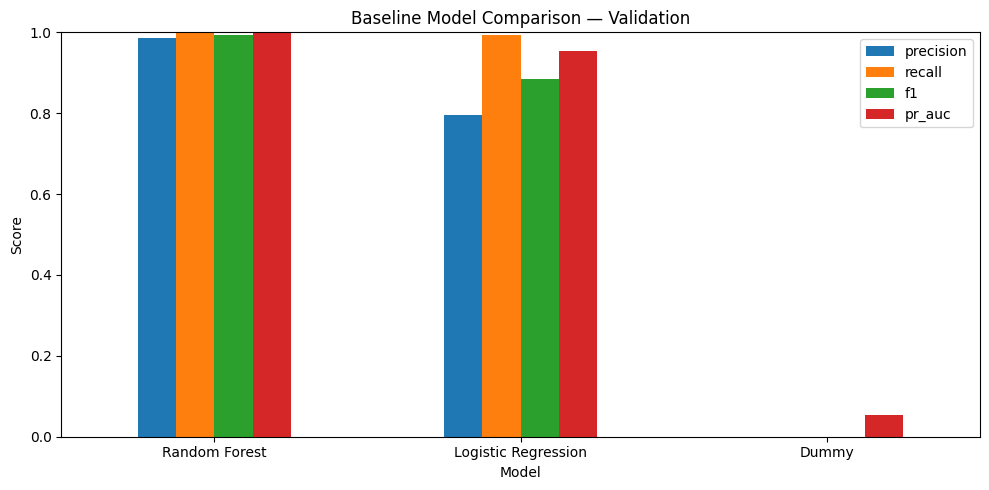

In [18]:

# ============================================================
# 10. COMPARE MODEL PERFORMANCE VISUALLY
# ============================================================

metrics_to_plot = [
    "precision",
    "recall",
    "f1",
    "pr_auc"
]

ax = (
    results_df.set_index("model")[metrics_to_plot]
    .plot(kind="bar", figsize=(10, 5))
)

ax.set_title("Baseline Model Comparison — Validation")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xlabel("Model")

plt.xticks(rotation=0)
plt.legend(loc="best")
plt.tight_layout()

plt.savefig(
    EVALUATION_DIR / "model_comparison.png",
    dpi=150
)
plt.show()


Classification report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     29080
      Attack       0.99      1.00      0.99      1632

    accuracy                           1.00     30712
   macro avg       0.99      1.00      1.00     30712
weighted avg       1.00      1.00      1.00     30712



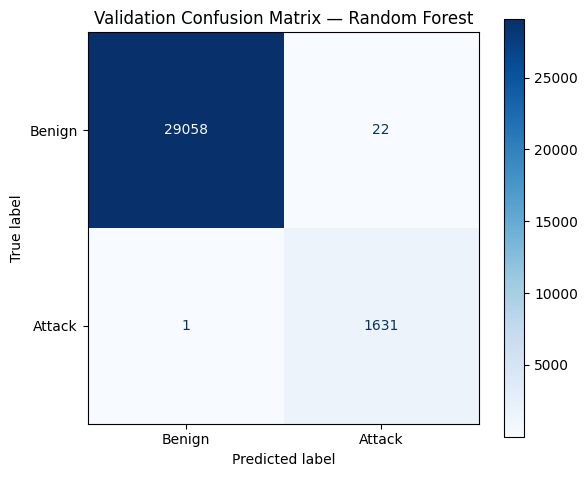

In [19]:

# ============================================================
# 11. CONFUSION MATRIX
# ============================================================

# Use validation predictions.
y_val_pred = best_model.predict(X_val)

print("Classification report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Benign", "Attack"],
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    display_labels=["Benign", "Attack"],
    cmap="Blues",
    ax=ax,
    values_format="d"
)

ax.set_title(
    f"Validation Confusion Matrix — {best_model_name}"
)

plt.tight_layout()
plt.savefig(
    EVALUATION_DIR / "confusion_matrix.png",
    dpi=150
)
plt.show()


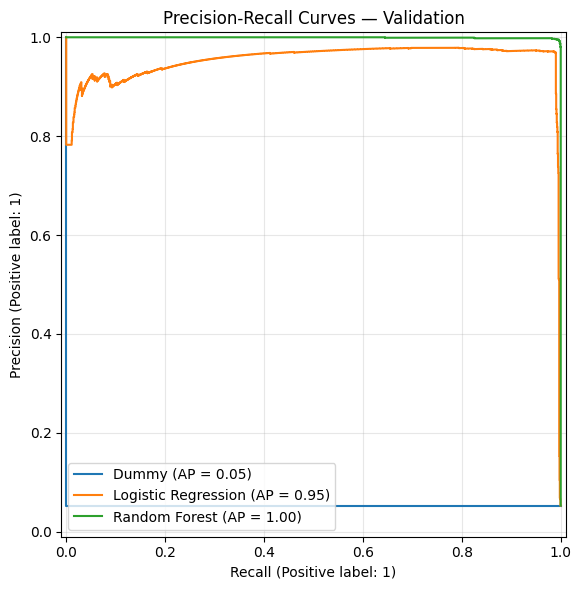

In [20]:

# ============================================================
# 12. PRECISION-RECALL CURVES
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    PrecisionRecallDisplay.from_predictions(
        y_val,
        probabilities,
        name=name,
        ax=ax
    )

ax.set_title("Precision-Recall Curves — Validation")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    EVALUATION_DIR / "precision_recall_curves.png",
    dpi=150
)
plt.show()


In [21]:

# ============================================================
# 13. FINAL HOLDOUT TEST EVALUATION
# ============================================================

# IMPORTANT:
# We have already selected the best model using validation.
# We now evaluate that fixed model on the untouched test set.
# Do not use these results to tune parameters repeatedly.

test_pred = best_model.predict(X_test)
test_proba = best_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "accuracy": float(
        accuracy_score(y_test, test_pred)
    ),
    "precision": float(
        precision_score(y_test, test_pred, zero_division=0)
    ),
    "recall": float(
        recall_score(y_test, test_pred, zero_division=0)
    ),
    "f1": float(
        f1_score(y_test, test_pred, zero_division=0)
    ),
    "pr_auc": float(
        average_precision_score(y_test, test_proba)
    )
}

print("Selected model:", best_model_name)
print("\nFinal holdout test metrics:")

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")


Selected model: Random Forest

Final holdout test metrics:
accuracy: 0.9996
precision: 0.9932
recall: 1.0000
f1: 0.9966
pr_auc: 0.9996


In [22]:

# ============================================================
# 14. SAVE MODEL AND RESULTS
# ============================================================

# Save the complete fitted pipeline.
# This includes preprocessing and the trained classifier.
# It will later be useful for inference and deployment.

model_path = MODEL_DIR / "baseline_model.joblib"

joblib.dump(best_model, model_path)

# Save validation results for model comparison.
results_df.to_csv(
    EVALUATION_DIR / "validation_model_comparison.csv",
    index=False
)

# Save the selected features for reproducibility.
with open(
    EVALUATION_DIR / "feature_columns.json", "w"
) as f:
    json.dump(feature_columns, f, indent=2)

# Save metrics in a machine-readable format.
# DVC will later use JSON metrics to track experiments.
experiment_metrics = {
    "selected_model": best_model_name,
    "validation": results_df.set_index("model")[
        ["accuracy", "precision", "recall", "f1", "pr_auc"]
    ].round(6).to_dict(orient="index"),
    "test": test_metrics
}

with open(
    EVALUATION_DIR / "metrics.json", "w"
) as f:
    json.dump(experiment_metrics, f, indent=2)

print("Model saved to:", model_path)
print("Evaluation results saved to:", EVALUATION_DIR)


Model saved to: /Users/arwaaldhuraibi/mlops-project-2026/models/baseline_model.joblib
Evaluation results saved to: /Users/arwaaldhuraibi/mlops-project-2026/evaluation



## Conclusion — Chapter 1.1

### What we implemented

In this notebook, we developed an initial machine learning
experiment for binary network intrusion detection.

We:

1. Loaded and inspected the NF-UNSW-NB15-v3 dataset.
2. Selected a reproducible modeling sample.
3. Examined class imbalance.
4. Excluded potentially leaking identifiers.
5. Created group-aware train, validation and test partitions.
6. Trained Dummy, Logistic Regression and Random Forest models.
7. Compared models using classification metrics.
8. Evaluated the selected model on a holdout test set.
9. Saved the fitted model and evaluation results.

### What we learned

Accuracy alone is insufficient for imbalanced intrusion
detection because attacks represent a minority of flows.

We therefore consider attack recall, precision, F1-score,
and precision-recall performance.

We also account for duplicate feature vectors during
dataset splitting to reduce overly optimistic evaluation.

### Limitations

- We used a subset of the complete dataset.
- Group-aware splitting does not fully simulate future traffic.
- We have not yet evaluated temporal generalization.
- Hyperparameter tuning was intentionally limited.
- Data drift monitoring has not yet been implemented.

### Next steps — MLOps

In Chapter 1.2, we will convert this notebook into:

- prepare.py
- train.py
- evaluate.py

Then, in Chapters 1.3–1.5, we will implement Git and DVC
to make the experiment reproducible.

In Chapter 2, we will move the pipeline to the cloud
and use GitHub Actions for automated experiments.

Our later project stages will include model deployment,
data drift detection and monitoring.
